In [ ]:

import torch
import torchvision

print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))



PyTorch Version: 2.14.1+cu130
Torchvision Version: 0.29.1+cu130
Device: cuda
GPU: Tesla T4


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

# Normalize MNIST images
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Load training dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Load testing dataset
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 495kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.64MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.7MB/s]

Training samples: 60000
Testing samples: 10000
Image shape: torch.Size([1, 28, 28])


In [ ]:

batch_size = 128

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# Testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])


Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
First 10 labels: tensor([9, 3, 2, 8, 2, 2, 1, 2, 3, 5])


In [ ]:

# Create ResNet18 from scratch
model = models.resnet18(weights=None)

# Change input layer for grayscale images
model.conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=64,
    kernel_size=3,
    stride=1,
    padding=1,
    bias=False
)

# Remove max pooling for small MNIST images
model.maxpool = nn.Identity()

# Change output layer for 10 digit classes
model.fc = nn.Linear(
    in_features=512,
    out_features=10
)

# Move model to GPU
model = model.to(device)

print("ResNet18 model created successfully!")
print("Model device:", next(model.parameters()).device)
print("Output classes:", model.fc.out_features)


ResNet18 model created successfully!
Model device: cuda:0
Output classes: 10


In [ ]:

# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training configuration
epochs = 5

print("Loss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Epochs:", epochs)
print("Model is ready for training!")


Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001
Epochs: 5
Model is ready for training!


In [ ]:

import time

train_losses = []
train_accuracies = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    start_time = time.time()

    for images, labels in train_loader:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()

        # Update weights
        optimizer.step()

        # Calculate training statistics
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    # Calculate epoch metrics
    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    epoch_time = time.time() - start_time

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}% "
        f"Time: {epoch_time:.2f}s"
    )

print("\nTraining completed successfully!")


Epoch [1/5] Loss: 0.0980 Accuracy: 96.95% Time: 58.53s
Epoch [2/5] Loss: 0.0372 Accuracy: 98.87% Time: 55.94s
Epoch [3/5] Loss: 0.0274 Accuracy: 99.11% Time: 57.04s
Epoch [4/5] Loss: 0.0251 Accuracy: 99.24% Time: 56.31s
Epoch [5/5] Loss: 0.0200 Accuracy: 99.40% Time: 56.64s

Training completed successfully!


In [ ]:

model.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

# Calculate test results
test_loss = test_loss / total
test_accuracy = 100 * correct / total

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 2), "%")
print("Correct Predictions:", correct)
print("Total Test Images:", total)


Test Loss: 0.017
Test Accuracy: 99.45 %
Correct Predictions: 9945
Total Test Images: 10000


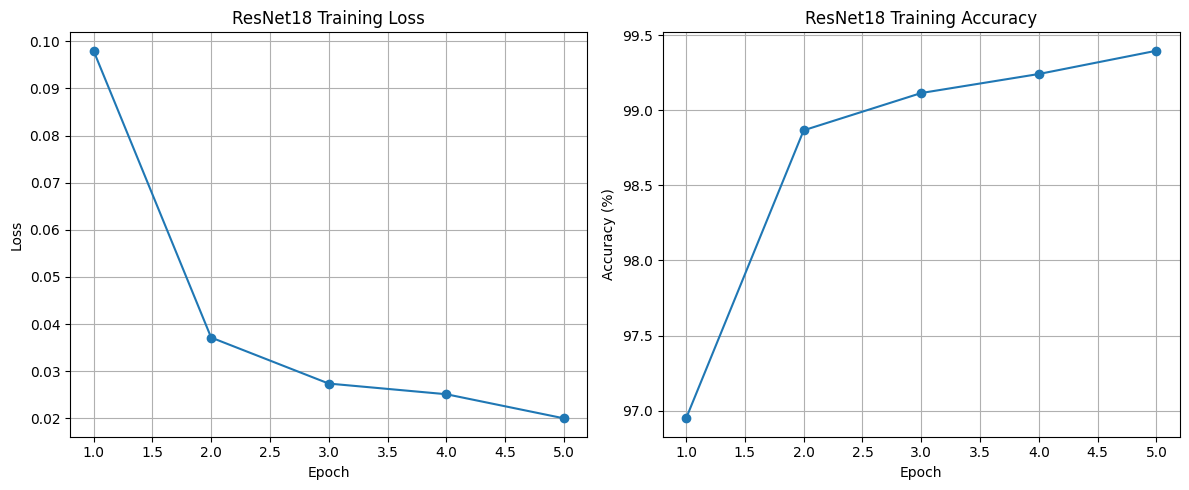

In [ ]:

import matplotlib.pyplot as plt

# Create figure
plt.figure(figsize=(12, 5))

# Training Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), train_losses, marker='o')
plt.title("ResNet18 Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

# Training Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), train_accuracies, marker='o')
plt.title("ResNet18 Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)

plt.tight_layout()
plt.show()


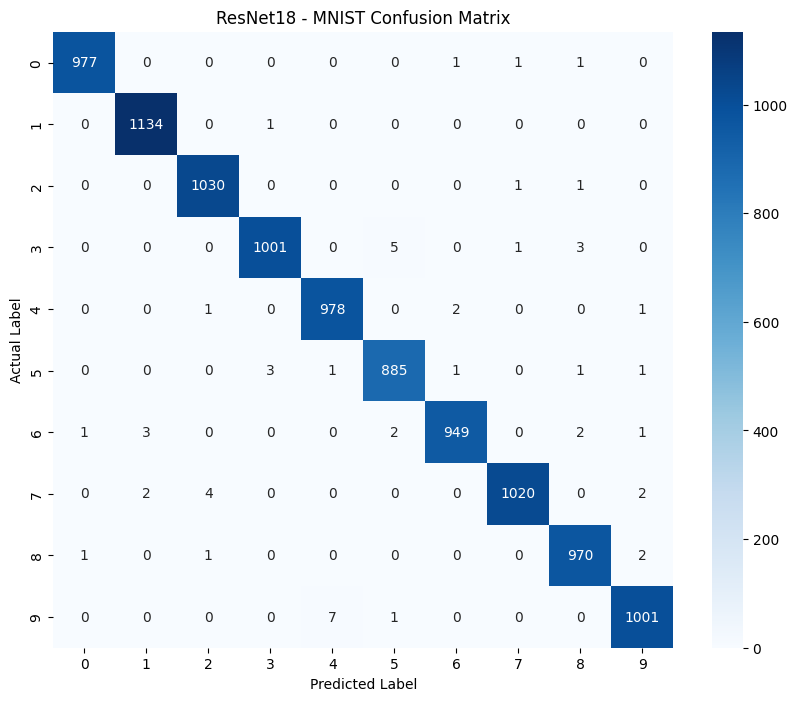

Classification Report:

              precision    recall  f1-score   support

           0     0.9980    0.9969    0.9974       980
           1     0.9956    0.9991    0.9974      1135
           2     0.9942    0.9981    0.9961      1032
           3     0.9960    0.9911    0.9935      1010
           4     0.9919    0.9959    0.9939       982
           5     0.9910    0.9922    0.9916       892
           6     0.9958    0.9906    0.9932       958
           7     0.9971    0.9922    0.9946      1028
           8     0.9918    0.9959    0.9939       974
           9     0.9931    0.9921    0.9926      1009

    accuracy                         0.9945     10000
   macro avg     0.9944    0.9944    0.9944     10000
weighted avg     0.9945    0.9945    0.9945     10000



In [ ]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Generate confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("ResNet18 - MNIST Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

# Classification report
print("Classification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4
    )
)


In [ ]:

# Save trained model weights
torch.save(
    model.state_dict(),
    "resnet18_mnist.pth"
)

print("Model saved successfully!")

# Save training and testing results
results = {
    "train_losses": train_losses,
    "train_accuracies": train_accuracies,
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "epochs": epochs,
    "batch_size": batch_size
}

torch.save(results, "training_results.pth")

print("Training results saved successfully!")


Model saved successfully!
Training results saved successfully!


In [ ]:
# Create a fresh ResNet18 model
loaded_model = models.resnet18(weights=None)

# Modify architecture exactly as before
loaded_model.conv1 = nn.Conv2d(
    1, 64, kernel_size=3, stride=1, padding=1, bias=False
)

loaded_model.maxpool = nn.Identity()

loaded_model.fc = nn.Linear(512, 10)

# Load saved weights
loaded_model.load_state_dict(
    torch.load("resnet18_mnist.pth", map_location=device)
)

# Move model to GPU
loaded_model = loaded_model.to(device)

# Set model to evaluation mode
loaded_model.eval()

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [ ]:
# Get one image from test dataset
image, true_label = test_dataset[0]

# Add batch dimension and move to GPU
image = image.unsqueeze(0).to(device)

# Set both models to evaluation mode
model.eval()
loaded_model.eval()

# Make predictions
with torch.no_grad():

    original_output = model(image)
    loaded_output = loaded_model(image)

    original_prediction = original_output.argmax(dim=1).item()
    loaded_prediction = loaded_output.argmax(dim=1).item()

# Compare model outputs
same_output = torch.allclose(
    original_output,
    loaded_output,
    atol=1e-6
)

print("Actual Digit:", true_label)
print("Original Model Prediction:", original_prediction)
print("Loaded Model Prediction:", loaded_prediction)
print("Both Models Match:", same_output)

Actual Digit: 7
Original Model Prediction: 7
Loaded Model Prediction: 7
Both Models Match: True


Saving Handwritten Black Number Seven.png to Handwritten Black Number Seven.png


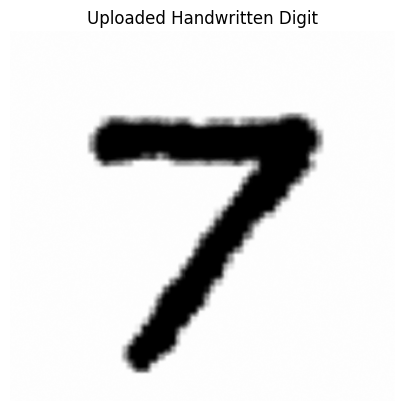

In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

# Upload handwritten digit image
uploaded = files.upload()

# Get uploaded image filename
image_path = next(iter(uploaded))

# Open image
img = Image.open(image_path).convert("L")

# Display uploaded image
plt.imshow(img, cmap="gray")
plt.title("Uploaded Handwritten Digit")
plt.axis("off")
plt.show()

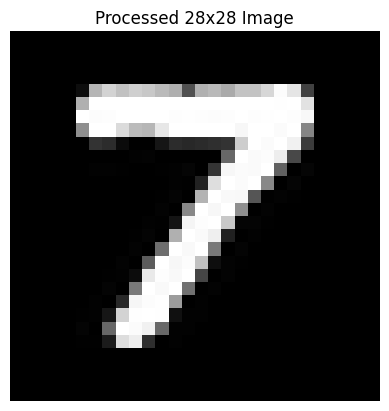

Predicted Digit: 7
Prediction Confidence: 96.91 %


In [ ]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

# Open uploaded image
img = Image.open(image_path).convert("L")

# Invert image: black background, white digit
img = ImageOps.invert(img)

# Find digit boundaries
binary = img.point(lambda p: 255 if p > 30 else 0)
bbox = binary.getbbox()

# Crop digit
digit = binary.crop(bbox)

# Resize digit while maintaining proportions
ratio = min(20 / digit.width, 20 / digit.height)

new_size = (
    max(1, int(digit.width * ratio)),
    max(1, int(digit.height * ratio))
)

digit = digit.resize(new_size, Image.Resampling.LANCZOS)

# Place digit in a 28x28 black canvas
canvas = Image.new("L", (28, 28), 0)

position = (
    (28 - new_size[0]) // 2,
    (28 - new_size[1]) // 2
)

canvas.paste(digit, position)

# Apply same normalization used during training
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

input_image = preprocess(canvas).unsqueeze(0).to(device)

# Display processed image
plt.imshow(canvas, cmap="gray")
plt.title("Processed 28x28 Image")
plt.axis("off")
plt.show()

# Predict using saved model
loaded_model.eval()

with torch.no_grad():
    output = loaded_model(input_image)
    probabilities = torch.softmax(output, dim=1)
    prediction = output.argmax(dim=1).item()
    confidence = probabilities[0][prediction].item() * 100

print("Predicted Digit:", prediction)
print("Prediction Confidence:", round(confidence, 2), "%")